# Classification of Paddock Polygons 
Modified version of the 'Machine learning with the Open Data Cube' Notebook

## Description

This notebook implements a workflow using functions from the [dea_tools.classification](../Tools/dea_tools/classification.py) script to implement a supervised learning classifier within the [ODC (Open Data Cube)](https://www.opendatacube.org/) framework. 

This classifies sugarcane crops into one or two year old crops in the Palmers Island and Palmers Channel area in northern NSW.

### Load packages
Import Python packages that are used for the analysis.

In [43]:
%matplotlib inline

import subprocess as sp
import shapely
import xarray as xr
import rasterio
import datacube
import matplotlib
import pydotplus
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from io import StringIO
from odc.io.cgroups import get_cpu_quota
from sklearn import tree
from sklearn import model_selection
from sklearn.metrics import accuracy_score
from IPython.display import Image
from datacube.utils import geometry
from datacube.utils.cog import write_cog
from dea_tools.datahandling import load_ard
from dea_tools.plotting import display_map, rgb  # load the rgb preview code
from odc.geo.xr import rasterize
from rasterio.features import geometry_mask
from matplotlib.colors import ListedColormap
from dea_tools.dask import create_local_dask_cluster
from matplotlib.patches import Patch


import sys
sys.path.insert(1, '../Tools/')
from dea_tools.classification import collect_training_data, predict_xr

import warnings
warnings.filterwarnings("ignore")

In [27]:
import pandas as pd

### Connect to the datacube

Connect to the datacube so we can access DEA data.

In [28]:
dc = datacube.Datacube(app='Classification_Sugar_Age')

In [29]:
# Create local dask cluster to improve data load time
client = create_local_dask_cluster(return_client=True) 

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/e.m.rose@student.uq.edu.au/proxy/35947/status,
Dashboard: /user/e.m.rose@student.uq.edu.au/proxy/35947/status,Workers: 1
Total threads: 96,Total memory: 14.25 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:46631,Workers: 0
Dashboard: /user/e.m.rose@student.uq.edu.au/proxy/35947/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36829,Total threads: 96
Dashboard: /user/e.m.rose@student.uq.edu.au/proxy/34939/status,Memory: 14.25 GiB
Nanny: tcp://127.0.0.1:46035,


### Automatically detect the number of cpus

In [30]:
import joblib

# Takes into account Docker/Kubernetes CPU quotas and task affinity
ncpus = joblib.cpu_count()
print(f"Allocated CPU Quota: {ncpus}")

Allocated CPU Quota: 2


### Define Functions for Training and Classification

In [31]:
def custom_function(query): 
    
    # Initialise datacube
    dc = datacube.Datacube(app='custom_feature_layers')

    # Load data using query
    result = load_ard(
        dc=dc,
        products=[
            'ga_s2am_ard_3',
            'ga_s2bm_ard_3',
            'ga_s2cm_ard_3'
        ],
        cloud_mask='s2cloudless',
        min_gooddata=0.99,
        dask_chunks={'time': 1},
        **query,
    )

    
    return result


In [32]:
def collect_training_data_from_ds(
    training_polygons,
    query,
    training_variables,
    class_column="id"
):

    training_data_options = custom_function(query)

    # pick the last time step (closest to the start of harvest season), and visually check
    training_data = training_data_options.isel(time=len(training_data_options.time)-1)
    
    plot_training(training_data, training_polygons)

    model_variables = list(training_data.data_vars)
    
    records = []
    class_ids = []

    for _, row in training_polygons.iterrows():

        # Mask pixels inside polygon
        mask = geometry_mask(
            [row.geometry],
            out_shape=(len(training_data.y), len(training_data.x)),
            transform=training_data.geobox.transform,
            invert=True
        )

        # Extract only pixels within polygon
        polygon_ds = training_data.where(mask)

        # Get values for all model variables
        arrays = {
            var: polygon_ds[var].values
            for var in model_variables
        }

        # Keep pixels where ALL model variables are valid
        valid = np.ones(
            arrays[model_variables[0]].shape,
            dtype=bool
        )

        for var in model_variables:
            valid &= np.isfinite(arrays[var])
    
        for pixel_values in zip(
            *[arrays[var][valid] for var in model_variables]
        ):
    
            records.append(pixel_values)
            class_ids.append(row[class_column])
    
    
    df = pd.DataFrame(
        records,
        columns=model_variables
    )
    
    df.index = class_ids
    df.index.name = "CLASS_ID"

    return df[training_variables]

In [33]:
def training(time_range, field, path_training, output_file):
    training_polygons = gpd.read_file(path_training)
    training_polygons.id = pd.to_numeric(training_polygons.id) # change data type to integer. 0 = fallow, 1 = 1 yr old, 2 = 2 yr old
    
    training_variables = ['nbart_coastal_aerosol', 'nbart_blue', 'nbart_green','nbart_red', 'nbart_red_edge_1', 'nbart_red_edge_2', 'nbart_red_edge_3','nbart_nir_1', 'nbart_nir_2', 'nbart_swir_2', 'nbart_swir_3']

    minx, miny, maxx, maxy = training_polygons.total_bounds

    query = {
    "x": (minx, maxx),
    "y": (miny, maxy),
    "time": time_range,
    "resolution": (-10, 10),
    "output_crs": "EPSG:3577",
    "group_by": "solar_day"
    }

    df = collect_training_data_from_ds(
    training_polygons.to_crs('EPSG:3577'),
    query,
    training_variables,
    class_column=field)

    df.to_csv(output_file)

    column_names = df.columns
    model_variables = column_names 

    model = tree.DecisionTreeClassifier(max_depth=10, min_samples_leaf=2)

    # Train model
    X = df.values
    y = df.index.values
    
    # fit my model
    model.fit(X, y)
    
    return model, model_variables
    

    

In [40]:
def plot_training(ds, training_polygons):
    
    cmap = ListedColormap([
        "brown",
        "green",
        "gold"
    ])
    
    
    rgb(
        ds,
        bands=['nbart_red', 'nbart_red_edge_1', 'nbart_swir_3']
    )
    
    ax = plt.gca()

    training_polygons[training_polygons["id"] == 0].plot(
        ax=ax,
        column="id",
        categorical=True,
        facecolor='none',
        edgecolor="brown",
        linewidth=2
    )

    training_polygons[training_polygons["id"] == 1].plot(
        ax=ax,
        column="id",
        categorical=True,
        facecolor='none',
        edgecolor="lawngreen",
        linewidth=2
    )

    training_polygons[training_polygons["id"] == 2].plot(
        ax=ax,
        column="id",
        categorical=True,
        facecolor='none',
        edgecolor="gold",
        linewidth=2
    )

    legend_elements = [
        Patch(facecolor='none', edgecolor='brown',
              linewidth=2, label='Fallow'),
        Patch(facecolor='none', edgecolor='lawngreen',
              linewidth=2, label='1 yr old'),
        Patch(facecolor='none', edgecolor='gold',
              linewidth=2, label='2 yr old')
    ]

    ax.legend(
        handles=legend_elements,
        title='Training Classes',
        loc='upper right'
    )
    
    ax.set_title("Training Data (false colour)")

    plt.savefig('Results/training-data-2018.png')
    
    plt.show()    

In [35]:
def plot_feature_importance(model, model_variables, filename):

    plt.bar(x=model_variables, height=model.feature_importances_)
    plt.gca().set_ylabel('Importance', labelpad=10)
    plt.gca().set_xlabel('Variable', labelpad=10);
    plt.xticks(rotation=90);

    plt.savefig(filename)
    plt.show()
    

In [36]:

def polygon_predictor(query,model_variables): 

    #load last good data before harvest season 
    
    new_input_data = custom_function(query)

    print("Selecting the last good data ...")
    ds = new_input_data.isel(time=len(new_input_data.time)-1)
    
    # Load study site polygons
    gdf = gpd.read_file("study-site-polygons.shp")
    
    gdf = gdf.to_crs(new_input_data.odc.geobox.crs)
    
    transform = new_input_data.odc.geobox.transform
    height = new_input_data.odc.geobox.shape[0]
    width = new_input_data.odc.geobox.shape[1]
    
    polygon_features = []
    print('Computing mean polygon values...')
    for polygon in gdf.geometry:
    
        # Create mask for pixels inside this polygon
        mask = geometry_mask(
            [polygon],
            transform=transform,
            invert=True,
            out_shape=(height, width)
        )
    
        features = {}
    
        for band in model_variables:
    
            # Get raster values
            data = ds[band].values
    
            # Extract pixels inside polygon
            values = data[mask]
    
            # Remove NaN values
            values = values[np.isfinite(values)]
    
            # Calculate mean
            if len(values) > 0:
                features[band] = np.mean(values)
            else:
                features[band] = np.nan
    
        polygon_features.append(features)
    
    features_df = pd.DataFrame(polygon_features)
    gdf = gdf.reset_index(drop=True)
    
    gdf = pd.concat(
        [gdf, features_df],
        axis=1
    )

    #do the model prediction
    X_predict = gdf[model_variables]
    predicted = model.predict(X_predict)
    gdf["predicted"] = predicted

    

    print('Model prediction complete')

    return gdf, ds

In [37]:
def plot_output(ds, gdf, year):
    
    cmap = ListedColormap([
        "brown",
        "green",
        "gold"
    ])
    
    
    rgb(
        ds,
        bands=['nbart_red', 'nbart_green', 'nbart_blue']
    )
    
    ax = plt.gca()
    
    gdf.plot(
        ax=ax,
        column="predicted",
        categorical=True,
        legend=True,
        cmap=cmap,
        alpha=1,
        edgecolor="black",
        linewidth=0.5
    )
    
    ax.set_title(str(year) + " Age-based classification")

    plt.savefig('Results/classification-'+str(year)+'.png')
    
    plt.show()

### Run the functions to train, test and classify

In [41]:
### Training parameters

path_training = 'training-data.shp'  # polygons with training labels
output_file = 'Results/training_data.csv'

time_range = ("2018-04-01", "2018-05-31") # to match training data

field = 'id'  # field with the class IDs


Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 4 out of 12 time steps with at least 99.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Returning 4 time steps as a dask array


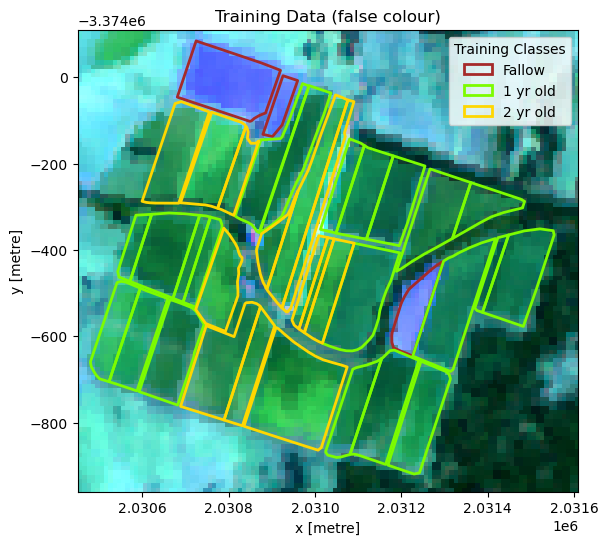

In [44]:
model, model_variables = training(time_range, field, path_training, output_file)

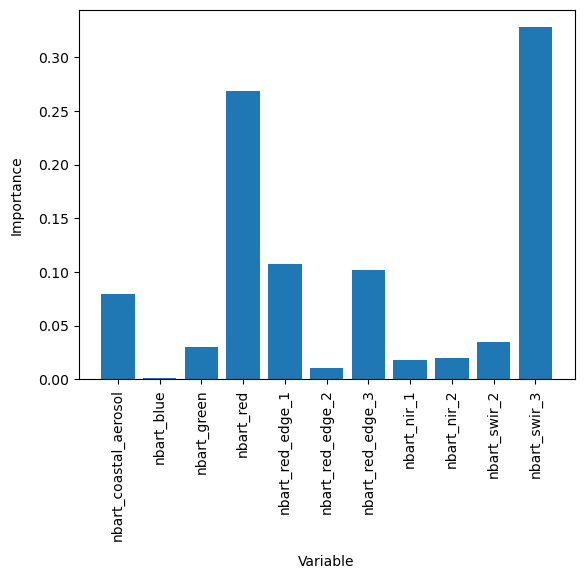

In [19]:
filename = 'Results/feature_importance.png'

plot_feature_importance(model, model_variables, filename)

In [20]:
#create output gpd
gdf = gpd.read_file("study-site-polygons.shp")
ages = gdf[['C_LINKCODE', 'geometry']]

In [21]:
years = np.arange(2016,2026)

for year in years:
    print("Classifying for "+str(year)+" ...")
    lat_range = (-29.4336, -29.4841)
    lon_range = (153.2438, 153.2906)

    query = {
        'x': lon_range,
        'y': lat_range,
        "time": (str(year)+"-04-01", str(year)+"-05-31"),
        "resolution": (-10, 10),
        "output_crs": "EPSG:3577",
    }

    gdf, ds = polygon_predictor(query,model_variables)

    ages[str(year)] = ages['C_LINKCODE'].map(gdf.set_index('C_LINKCODE')['predicted'])

    print()

    #plot_output(ds, gdf, year)

Classifying for 2016 ...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 3 out of 6 time steps with at least 99.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Returning 3 time steps as a dask array
Selecting the last good data ...
Computing mean polygon values...
Model prediction complete

Classifying for 2017 ...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 3 out of 7 time steps with at least 99.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Returning 3 time steps as a dask array
Selecting the last good data ...
Computing mean polygon values...
Model prediction complete

Classifying for 2018 ...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filterin

In [22]:
ages_filename = 'Results/age_classification.csv'
ages.to_csv(ages_filename)

In [23]:
## reload ages data if script has been idle
ages = pd.read_csv('Results/age_classification.csv')

In [24]:

# Add some logic to improve classification - particularly improve 1 yr old paddocks misclassified as 2 yr

# Can't improve classification for the first year
yrs = years[1:]

# Load harvest classification
harvest_class = pd.read_csv(
    'Results/harvest_classification.csv',
    index_col='C_LINKCODE'
)

# Create independent copy, indexed by paddock ID
updated_ages = ages.set_index('C_LINKCODE').copy()

ages_fixed = 0

for year in yrs:
    last_year = year - 1

    for paddock, row in updated_ages.iterrows():

        # Get ages for the previous and current years
        age_last = row[str(last_year)]
        age_this = row[str(year)]

        # Get harvest status for the previous year
        harvested_last = harvest_class.loc[paddock, str(last_year)]

        # Skip missing age values
        if pd.isna(age_last) or pd.isna(age_this):
            continue

        # Correct implausible age transitions
        if age_this > age_last + 1:
            updated_ages.loc[paddock, str(year)] = 1
            ages_fixed += 1

        elif harvested_last and age_this == 2:
            updated_ages.loc[paddock, str(year)] = 1
            ages_fixed += 1

        

print(f"Number of cells fixed: {ages_fixed}")

updated_ages

Number of cells fixed: 954


,Unnamed: 0,geometry,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
C_LINKCODE,,,,,,,,,,,,
1017-00220,0,POLYGON ((2028480.2227518638 -3368972.28179805...,1,0,1,1,2,2,1,2,1,2
1017-00320,1,POLYGON ((2028457.359678622 -3369081.246338725...,1,1,1,1,2,1,2,1,1,1
1017-00330,2,POLYGON ((2028446.2439035226 -3369118.49732156...,2,1,2,1,2,1,2,1,2,1
1017-00410,3,POLYGON ((2028370.5678526706 -3369144.68299171...,1,1,1,1,1,2,1,2,1,1
1017-00420,4,POLYGON ((2028429.7970159599 -3369162.01721538...,1,1,1,2,1,2,1,2,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...
2149-00420,486,POLYGON ((2030317.5197796826 -3369566.74423886...,1,1,1,1,1,2,1,2,1,1
2149-00430,487,POLYGON ((2030303.9575278023 -3369609.83767452...,2,2,1,1,1,2,1,2,1,1
2149-00500,488,POLYGON ((2030062.7281695008 -3369445.24199706...,2,1,1,2,1,2,1,2,2,1


In [25]:
updated_ages.to_csv(ages_filename)